# Assignment 3 — Building the Pricing Library

Starting point: the five lecture solution files.

## 3(a) European digital options
A unit cash-or-nothing **call** pays 1 when $S_T>K$; a **put** pays 1 when $S_T<K$. Both pay zero at equality. Short positions reverse every payoff, price and Greek.

With no dividends, constant rate $r$, volatility $\sigma$, remaining time $\tau=T-t$, and $q=1$ for calls or $q=-1$ for puts:
$$b=\sigma\sqrt{\tau},\quad d_2=\frac{\log(S/K)+(r-\sigma^2/2)\tau}{b},\quad d_1=d_2+b,\quad D=e^{-r\tau}.$$
$$V=DN(qd_2),\quad \Delta=\frac{qD\phi(d_2)}{Sb},\quad \Gamma=-\frac{qD\phi(d_2)}{S^2b}\left(1+\frac{d_2}{b}\right),\quad \text{Vega}=-\frac{qD\phi(d_2)d_1}{\sigma}.$$
$$\Theta=rV-qD\phi(d_2)\left(\frac{r-\sigma^2/2}{b}-\frac{d_2}{2\tau}\right),\qquad \rho=-\tau V+\frac{qD\phi(d_2)\sqrt{\tau}}{\sigma}.$$
Here $N$ is the standard normal CDF and $\phi$ its density. Theta measures calendar-time change per year; vega and rho are per unit volatility/rate change. Multiply by $0.01$ for a one-percentage-point sensitivity.

Implemented in `contract.py` and `pricer.py`; fair-value and additional validation tests are in `test_digital.py`.


In [1]:
import sys
from pathlib import Path
from copy import deepcopy
import numpy as np
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
if cwd.name == "Homework_3" and (cwd / "contract.py").is_file():
    folder = cwd
elif (cwd / "Homework_3" / "contract.py").is_file():
    folder = cwd / "Homework_3"
else:
    folder = cwd / "homeworks/67241ae/rest_of_homework/Homework_3"
if not (folder / "contract.py").is_file():
    raise RuntimeError("Open the notebook from Homework_3 or the course repository root.")
repo = next((parent for parent in [folder, *folder.parents] if (parent / "src/enums.py").is_file()), None)
if repo is not None:
    sys.path.insert(0, str(repo))
sys.path.insert(0, str(folder.parent))
from Homework_3.contract import EuropeanContract, EuropeanDigitalContract
from Homework_3.model import MarketModel
from Homework_3.pricer import EuropeanAnalyticPricer, EuropeanDigitalAnalyticPricer, Params
from Homework_3.enums import Stock, PutCallFwd, LongShort

underlying = Stock.BLUECHIP_BANK
model = MarketModel(underlying)
model.spot, model.vol, model.risk_free_rate = 100., .20, .05
strike, expiry = 100., 1.
call_contract = EuropeanDigitalContract(underlying, PutCallFwd.CALL, LongShort.LONG, strike, expiry)
put_contract = EuropeanDigitalContract(underlying, PutCallFwd.PUT, LongShort.LONG, strike, expiry)
call = EuropeanDigitalAnalyticPricer(call_contract, model, Params())
put = EuropeanDigitalAnalyticPricer(put_contract, model, Params())
print("Unit payout | S = K = 100 | T = 1 year | r = 5% | sigma = 20%")
print(f'{"Measure":>12} {"Call":>15} {"Put":>15}')
for measure in ["fair_value", "delta", "gamma", "vega", "theta", "rho"]:
    print(f'{measure:>12} {getattr(call, "calc_"+measure)():15.10f} {getattr(put, "calc_"+measure)():15.10f}')
print(f"Call + put: {call.calc_fair_value() + put.calc_fair_value():.10f}")
print(f"Discount factor: {model.calc_df(expiry):.10f}")
np.testing.assert_allclose(call.calc_fair_value() + put.calc_fair_value(), model.calc_df(expiry), atol=1e-12)
for terminal in [90., 100., 110.]:
    print(f"S_T={terminal:g}: call payoff={call_contract.payoff({expiry: terminal}):g}, put payoff={put_contract.payoff({expiry: terminal}):g}")


Unit payout | S = K = 100 | T = 1 year | r = 5% | sigma = 20%
     Measure            Call             Put
  fair_value    0.5323248155    0.4189046090
       delta    0.0187620173   -0.0187620173
       gamma   -0.0003283353    0.0003283353
        vega   -0.6566706071    0.6566706071
       theta   -0.0015267852    0.0490882565
         rho    1.3438769191   -2.2951063436
Call + put: 0.9512294245
Discount factor: 0.9512294245
S_T=90: call payoff=0, put payoff=1
S_T=100: call payoff=0, put payoff=0
S_T=110: call payoff=1, put payoff=0


### Unit tests
Run both the original lecture parity tests and the new digital tests. Digital fair values are checked against numerical integration of the risk-neutral normal density and a known numerical example. Further tests check payoffs, long/short signs, parity and Greeks against central differences.


In [2]:
import subprocess
completed = subprocess.run(
    [sys.executable, "-m", "pytest", str(folder / "test_pricer.py"), str(folder / "test_digital.py"), "-q"],
    cwd=folder.parent, capture_output=True, text=True
)
print(completed.stdout)
if completed.returncode != 0:
    print(completed.stderr)
    raise RuntimeError("Tests failed; inspect the output above.")


........................................................................ [ 56%]
.......................................................                  [100%]
127 passed in 0.48s



## 3(b) Digital call as a limit of bull call spreads
Buy $1/h$ calls at strike $K$ and sell $1/h$ calls at strike $K+h$:
$$B_h(S_T)=\frac{(S_T-K)^+-(S_T-K-h)^+}{h}.$$
The payoff is zero below $K$, increases linearly from zero to one over $[K,K+h]$, then stays at one. As $h\downarrow0$, it converges pointwise to the unit digital call payoff.

The corresponding price satisfies
$$\frac{C(S,K)-C(S,K+h)}{h}\longrightarrow-\frac{\partial C}{\partial K}=e^{-r\tau}N(d_2).$$
**Dividing by the strike gap is essential:** an unscaled spread's payoff and price approach zero.

We use both the lecture's `EuropeanAnalyticPricer` and the new `EuropeanDigitalAnalyticPricer`. The three panels compare payoffs, prices before maturity and the maximum absolute price error on the spot grid.


  Gap h      Spread at S=100     Digital at S=100     Max grid error
     10         0.4410495442         0.5323248155       9.127951e-02
      5         0.4858462674         0.5323248155       4.658696e-02
      1         0.5229535393         0.5323248155       9.455010e-03
    0.1         0.5313867947         0.5323248155       9.483899e-04


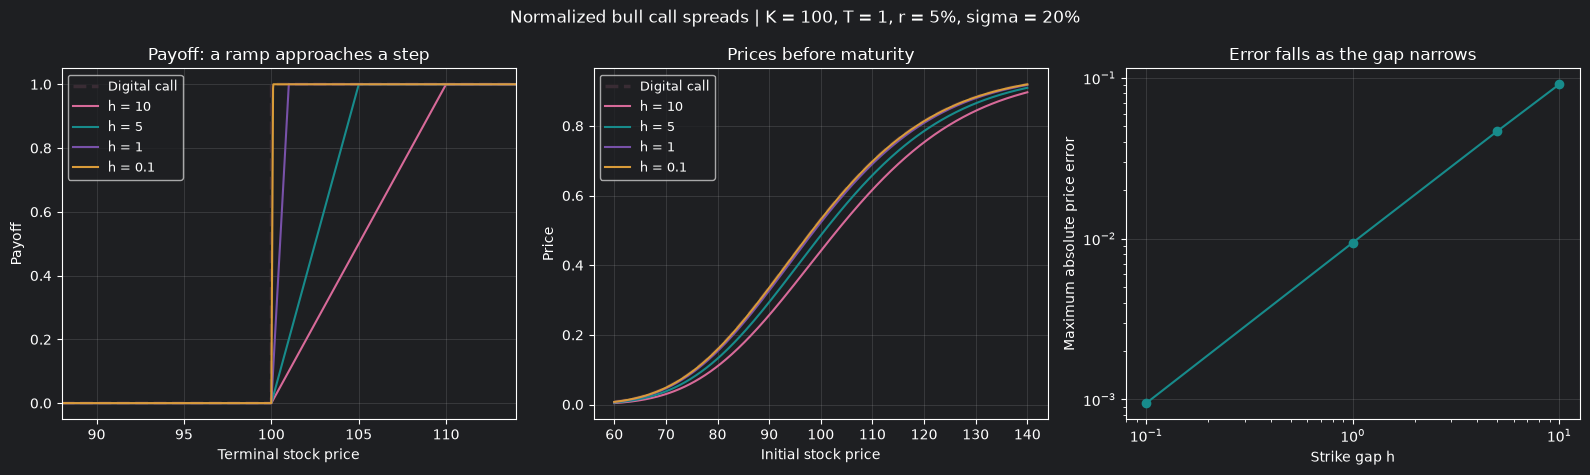

In [3]:
widths = [10., 5., 1., .1]
spots = np.linspace(60., 140., 401)
terminal_spots = np.unique(np.r_[np.linspace(88., 114., 1501), strike])
timeline = call_contract.get_timeline()[0]
colors = ["#D76A99", "#178B8B", "#7851A9", "#D99B39"]

def vanilla_pricer(K, position, spot):
    local_model = deepcopy(model)
    local_model.spot = spot
    contract = EuropeanContract(underlying, PutCallFwd.CALL, position, K, expiry)
    return EuropeanAnalyticPricer(contract, local_model, Params())

def digital_price(spot):
    local_model = deepcopy(model)
    local_model.spot = spot
    return EuropeanDigitalAnalyticPricer(call_contract, local_model, Params()).calc_fair_value()

digital_prices = np.array([digital_price(s) for s in spots])
digital_payoffs = [call_contract.payoff({timeline: s}) for s in terminal_spots]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
axes[0].plot(terminal_spots, digital_payoffs, color="#392C34", linestyle="--", linewidth=2.5, label="Digital call")
axes[1].plot(spots, digital_prices, color="#392C34", linestyle="--", linewidth=2.5, label="Digital call")
max_errors = []
print(f'{"Gap h":>7} {"Spread at S=100":>20} {"Digital at S=100":>20} {"Max grid error":>18}')
for width, color in zip(widths, colors):
    lower = vanilla_pricer(strike, LongShort.LONG, model.spot)
    upper = vanilla_pricer(strike + width, LongShort.SHORT, model.spot)
    payoffs = [(lower.contract.payoff({timeline: s}) + upper.contract.payoff({timeline: s}))/width for s in terminal_spots]
    prices = np.array([(vanilla_pricer(strike, LongShort.LONG, s).calc_fair_value()
                       + vanilla_pricer(strike + width, LongShort.SHORT, s).calc_fair_value())/width for s in spots])
    axes[0].plot(terminal_spots, payoffs, color=color, label=f"h = {width:g}")
    axes[1].plot(spots, prices, color=color, label=f"h = {width:g}")
    error = np.max(np.abs(prices - digital_prices))
    max_errors.append(error)
    spread_at_spot = (lower.calc_fair_value() + upper.calc_fair_value()) / width
    print(f'{width:7g} {spread_at_spot:20.10f} {call.calc_fair_value():20.10f} {error:18.6e}')
assert np.all(np.diff(max_errors) < 0)
assert max_errors[-1] < .002
axes[0].set(title="Payoff: a ramp approaches a step", xlabel="Terminal stock price", ylabel="Payoff", xlim=(88, 114))
axes[1].set(title="Prices before maturity", xlabel="Initial stock price", ylabel="Price")
axes[2].loglog(widths, max_errors, "o-", color="#178B8B")
axes[2].set(title="Error falls as the gap narrows", xlabel="Strike gap h", ylabel="Maximum absolute price error")
for ax in axes:
    ax.grid(True, alpha=.25)
for ax in axes[:2]:
    ax.legend(fontsize=9)
fig.suptitle("Normalized bull call spreads | K = 100, T = 1, r = 5%, sigma = 20%")
fig.tight_layout()
fig.savefig(folder / "digital_bull_spread.png", dpi=180, bbox_inches="tight")
plt.show()


## Conclusion
The digital call and put prices sum to the discounted unit payout. The analytic Greeks agree with finite-difference checks, and the fair-value tests pass.

As the gap between the two strikes decreases, the normalized bull spread's payoff becomes a sharper step and its price approaches the digital call price. The last panel measures this convergence on the chosen spot grid; it is not a claim about uniform convergence of the discontinuous payoff.

The implementation assumes no dividends and a constant interest rate and volatility. Prices also handle maturity and zero volatility using the deterministic payoff; analytic Greeks require strictly positive remaining time and volatility.
